# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [3]:
ROLL_NO = 10241270297          # <-- your full roll number
NAME = "Anwesha Goyal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [4]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [5]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [6]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 10241270297   Name: Anwesha Goyal   Fingerprint: 86976E09   Tickets: 14

Ticket_ID                                                                         Ticket_Text
      T01                       The printer was working yesterday. Is there another solution?
      T02                              The Matlab failed to open. I have tried several times!
      T03                 I tried restarting the VPN on my laptop. Is there another solution?
      T04                            I am unable to use the laptop on my laptop. Please help.
      T05                                       The Python failed to open. Please resolve it.
      T06                         Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T07                                      Re-installing didn't help; log-in still fails!
      T08 I keep getting logged out of the Python after the latest update. Please resolve it.
      T09                                                Python 3.12

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [7]:
import pandas as pd

# Step 1: Process every ticket
processed_data = []

for _, row in df.iterrows():

    result = process_ticket(row["Ticket_Text"])

    processed_data.append({
        "Ticket_ID": row["Ticket_ID"],
        "Number of Sentences": len(result["sentences"]),
        "Number of Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })


# Step 2: Create one table
preprocessing_df = pd.DataFrame(processed_data)

# Step 3: Add the total row
count_columns = [
    "Number of Sentences",
    "Number of Tokens",
    "Punctuation Tokens",
    "Stopwords",
    "Unique Tokens",
    "Final Tokens"
]

total_row = {"Ticket_ID": "TOTAL"}

for column in count_columns:
    total_row[column] = preprocessing_df[column].sum()

preprocessing_df.loc[len(preprocessing_df)] = total_row

# Step 4: Display the combined table
print("PREPROCESSING STATISTICS FOR ALL TICKETS")
display(preprocessing_df)


# Step 5: Display detailed preprocessing for one selected ticket
selected_ticket_id = "T01"

selected_text = df.loc[
    df["Ticket_ID"] == selected_ticket_id, "Ticket_Text"
].iloc[0]

result = process_ticket(selected_text)

print(f"\nDETAILED PREPROCESSING: {selected_ticket_id}")
print("Original Text:", selected_text)
print("\nActual Tokens:", result["tokens"])
print("\nPunctuation Tokens:", result["punct"])
print("\nStopwords:", result["stops"])
print("\nFinal Tokens:", result["final"])

PREPROCESSING STATISTICS FOR ALL TICKETS


,Ticket_ID,Number of Sentences,Number of Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,11,2,4,11,5
1,T02,2,12,2,4,12,6
2,T03,2,14,2,6,14,6
3,T04,2,14,2,6,12,6
4,T05,2,10,2,3,9,5
5,T06,1,9,2,2,9,5
6,T07,1,9,2,1,9,6
7,T08,2,17,2,7,15,8
8,T09,1,6,1,1,6,4
9,T10,2,13,2,5,12,6



DETAILED PREPROCESSING: T01
Original Text: The printer was working yesterday. Is there another solution?

Actual Tokens: ['the', 'printer', 'was', 'working', 'yesterday', '.', 'is', 'there', 'another', 'solution', '?']

Punctuation Tokens: ['.', '?']

Stopwords: ['the', 'was', 'is', 'there']

Final Tokens: ['printer', 'working', 'yesterday', 'another', 'solution']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* Tokens like n't, 's, and ca come from contractions such as doesn't, it's, and can't. NLTK's word_tokenize() splits contractions into smaller tokens, which remain because the preprocessing function does not explicitly remove them.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
import re

# Patterns for extraction
patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "All numbers": r"\b\d+(?:\.\d+)*\b",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words starting with a vowel": r"\b[AEIOUaeiou][a-zA-Z]*\b"
}

# Apply patterns to raw tickets
for name, pattern in patterns.items():
    print(f"\n{name}:")
    for _, row in df.iterrows():
        matches = re.findall(pattern, row["Ticket_Text"])
        if matches:
            print(row["Ticket_ID"], matches)

# Test patterns on TEST_LINES
print("\n--- TEST_LINES RESULTS ---")
for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nLine {i}: {line}")
    for name, pattern in patterns.items():
        print(f"{name}: {re.findall(pattern, line)}")


# Replace emails, URLs, and phone numbers
email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"https?://\S+|www\.\S+"
phone_pattern = r"(?<!\w)\+?\d[\d -]{7,}\d(?!\w)"

for line in TEST_LINES:
    cleaned = re.sub(email_pattern, "<EMAIL>", line)
    cleaned = re.sub(url_pattern, "<URL>", cleaned)
    cleaned = re.sub(phone_pattern, "<PHONE>", cleaned)
    print("\nOriginal:", line)
    print("Cleaned:", cleaned)



Words longer than 5 letters:
T01 ['printer', 'working', 'yesterday', 'another', 'solution']
T02 ['Matlab', 'failed', 'several']
T03 ['restarting', 'laptop', 'another', 'solution']
T04 ['unable', 'laptop', 'laptop', 'Please']
T05 ['Python', 'failed', 'Please', 'resolve']
T06 ['helpdesk', 'thapar', 'thapar']
T07 ['installing']
T08 ['getting', 'logged', 'Python', 'latest', 'update', 'Please', 'resolve']
T09 ['Python', 'installed', 'yesterday']
T10 ['failed', 'changed']
T11 ['Student', 'portal', 'stopped', 'syncing', 'uploading', 'Please']
T12 ['Server', 'failed', 'resetting', 'password']
T13 ['cannot', 'access', 'laptop', 'Please']

All numbers:
T09 ['3.12']

Capitalized words:
T01 ['The', 'Is']
T02 ['The', 'Matlab', 'I']
T03 ['I', 'VPN', 'Is']
T04 ['I', 'Please']
T05 ['The', 'Python', 'Please']
T06 ['Write']
T07 ['Re']
T08 ['I', 'Python', 'Please']
T09 ['Python']
T10 ['The', 'VPN', 'I']
T11 ['Student', 'Please']
T12 ['Server', 'Can']
T13 ['I', 'Please']
T14 ['The', 'Wi', 'Fi', 'VPN']

W

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Some capitalized words, such as The, may be capitalized only because they appear at the beginning of a sentence. Therefore, not every capitalized word is necessarily a proper noun. The exact count can be determined by comparing the capitalized-word matches with their positions in the original tickets.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [9]:
import re
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Custom tokenizer pattern
pattern = r"""https?://[^\s]+|www\.[^\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d[\d -]{7,}\d|\d+(?:\.\d+)+(?:[A-Za-z]+)?|[A-Za-z]+(?:[-'][A-Za-z]+)*|\d+|[^\w\s]"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)


# Test on TEST_LINES
print("TEST_LINES")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Custom tokens:", my_tokenize(line))
    print("NLTK tokens:", word_tokenize(line))


# Test on generated tickets
print("\nGENERATED TICKETS")

different_count = 0

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    different = custom_tokens != nltk_tokens

    if different:
        different_count += 1

    print(f"\nTicket: {row['Ticket_ID']}")
    print("Custom tokens:", custom_tokens)
    print("NLTK tokens:", nltk_tokens)
    print("Different:", different)

print("\nNumber of tickets tokenized differently:",
      different_count, "out of", len(df))

TEST_LINES

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK tokens: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom tokens: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK tokens: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Original: The state-of-the-art lab isn't open; log-in at 5.30 p

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* Out of 14 tickets,tickets are tokenized differently by my_tokenize() and word_tokenize() because the custom tokenizer keeps contractions, hyphenated words, decimals, email addresses, URLs, and phone numbers together as single tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [10]:
import nltk
import pandas as pd
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

# Download required resources
nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Initialize stemmers and lemmatizer
porter = PorterStemmer()
lancaster = LancasterStemmer()

# Custom suffix rule: remove common suffixes from words
regex_stemmer = RegexpStemmer(r'ing$|ed$|es$|s$', min=4)

lemmatizer = WordNetLemmatizer()


# Collect unique final tokens from all tickets
unique_final_tokens = set()

for text in df["Ticket_Text"]:
    result = process_ticket(text)
    unique_final_tokens.update(result["final"])


# Convert NLTK POS tags to WordNet POS tags
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN


# Compare the four methods
rows = []

for word in sorted(unique_final_tokens):

    pos = pos_tag([word])[0][1]
    wn_pos = get_wordnet_pos(pos)

    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regex_word = regex_stemmer.stem(word)
    lemma_word = lemmatizer.lemmatize(word, pos=wn_pos)

    # Show only words where at least one output differs
    if len(set([
        porter_word,
        lancaster_word,
        regex_word,
        lemma_word
    ])) > 1:

        rows.append({
            "Original Word": word,
            "Porter Stemmer": porter_word,
            "Lancaster Stemmer": lancaster_word,
            "Regexp Stemmer": regex_word,
            "WordNet Lemmatizer": lemma_word,
            "POS Tag": pos
        })


# Display the difference table
comparison_df = pd.DataFrame(rows)

print("Words where stemming and lemmatization outputs differ:")
display(comparison_df)

Words where stemming and lemmatization outputs differ:


,Original Word,Porter Stemmer,Lancaster Stemmer,Regexp Stemmer,WordNet Lemmatizer,POS Tag
0,access,access,access,acces,access,NN
1,another,anoth,anoth,another,another,DT
2,changed,chang,chang,chang,change,VBN
3,fails,fail,fail,fail,fails,NNS
4,file,file,fil,file,file,NN
5,getting,get,get,gett,get,VBG
6,installed,instal,instal,install,instal,VBN
7,latest,latest,latest,latest,late,JJS
8,logged,log,log,logg,log,VBN
9,open,open,op,open,open,JJ


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Over-stemming: If Lancaster Stemmer reduces a word to an excessively short root that loses its meaning, it is an example of over-stemming.
Under-stemming: If two words with the same root remain in different forms after stemming, it is an example of under-stemming

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Total Tokens,Unique Tokens,TTR
0,S1 - All tokens,165,85,0.5152
1,S2 - No punctuation,138,79,0.5725
2,S3 - Final tokens,80,53,0.6625
3,S4 - Porter stemmed,80,51,0.6375



TOP 10 WORDS IN S1
[('.', 19), ('the', 12), ('to', 6), ('i', 6), ('please', 5), ('failed', 4), ('open', 4), ('my', 4), ('laptop', 4), ('help', 4)]

TOP 10 WORDS IN S3
[('please', 5), ('failed', 4), ('open', 4), ('laptop', 4), ('help', 4), ('vpn', 3), ('python', 3), ("n't", 3), ('yesterday', 2), ('another', 2)]


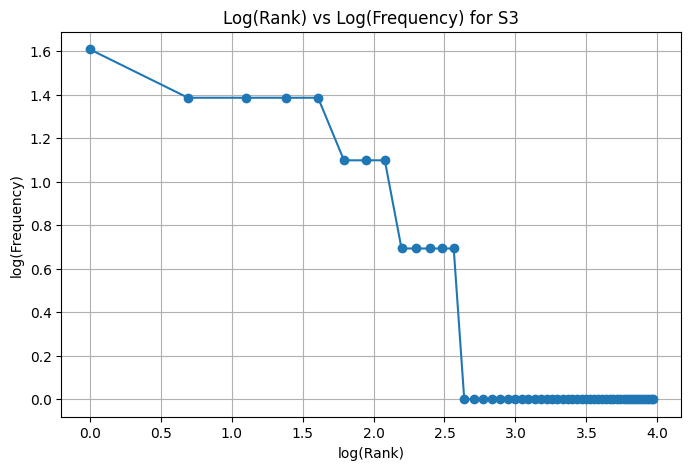


TOP 5 BIGRAMS IN S1
[(('.', 'please'), 5), (('failed', 'to'), 4), (('to', 'open'), 4), (('open', '.'), 3), (('the', 'vpn'), 3)]

TOP 5 BIGRAMS IN S3
[(('failed', 'open'), 4), (('please', 'help'), 3), (('another', 'solution'), 2), (('laptop', 'please'), 2), (('please', 'resolve'), 2)]


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from nltk.util import ngrams
from nltk.stem import PorterStemmer

# Initialize Porter Stemmer
porter = PorterStemmer()

# Create S1, S2, S3, and S4 using the generated tickets
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:
    result = process_ticket(text)

    # S1: All tokens
    S1.extend(result["tokens"])

    # S2: Tokens without punctuation
    S2.extend([t for t in result["tokens"] if t not in result["punct"]])

    # S3: Final tokens after removing punctuation and stopwords
    S3.extend(result["final"])

# S4: S3 after Porter stemming
S4 = [porter.stem(token) for token in S3]


# Calculate corpus statistics
def corpus_stats(tokens, name):
    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))
    ttr = unique_tokens / total_tokens if total_tokens else 0

    return {
        "Corpus": name,
        "Total Tokens": total_tokens,
        "Unique Tokens": unique_tokens,
        "TTR": round(ttr, 4)
    }


stats = pd.DataFrame([
    corpus_stats(S1, "S1 - All tokens"),
    corpus_stats(S2, "S2 - No punctuation"),
    corpus_stats(S3, "S3 - Final tokens"),
    corpus_stats(S4, "S4 - Porter stemmed")
])

print("CORPUS STATISTICS")
display(stats)


# Top 10 words of S1 and S3
print("\nTOP 10 WORDS IN S1")
print(Counter(S1).most_common(10))

print("\nTOP 10 WORDS IN S3")
print(Counter(S3).most_common(10))


# Log(rank) vs log(frequency) for S3
frequency = Counter(S3)
ranked_frequencies = sorted(frequency.values(), reverse=True)

ranks = np.arange(1, len(ranked_frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.plot(np.log(ranks), np.log(ranked_frequencies), marker="o")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()


# Top 5 bigrams of S1 and S3
print("\nTOP 5 BIGRAMS IN S1")
print(Counter(ngrams(S1, 2)).most_common(5))

print("\nTOP 5 BIGRAMS IN S3")
print(Counter(ngrams(S3, 2)).most_common(5))


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes because preprocessing removes punctuation and stopwords, while Porter stemming converts related words into common root forms. This changes the total and unique token counts. Stemming generally reduces vocabulary diversity, although the TTR may increase or decrease depending on the dataset.